---
title: "Reading probabilistic forecasts"
subtitle: "Where CPT's tercile probabilities come from, and what PyCPT's flexible forecasts change"
description: "Rebuild CPT's OND 2023 tercile probabilities from the deterministic forecast, its error variance and the observed climatology; compare PyCPT's construct_flex_fcst; check the forecast against what was observed."
execute:
  enabled: false
---

Chapter 4 ended with a map of the most likely category. This chapter opens that
map up. A CPT probability forecast is built from three numbers per location: the
deterministic forecast, a measure of how wrong such forecasts have been, and the
observed rainfall that defines "below", "near" and "above normal". We rebuild CPT's
probabilities from those numbers, then use PyCPT's `construct_flex_fcst` to ask
other questions, and finally look at what was observed in OND 2023.

The rules described here were found by reading the
[CPT 17.8.3 source code](https://doi.org/10.7916/fdp6-v391) and its session logs, and
every one of them is checked against CPT's own output in the cells below.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment and the case folder from chapters 1 to 4: the forecast
file written by `evaluate_models` in chapter 4 and the local CHIRPS v3.0 file from
chapter 3. Step 6 also reads the observed OND 2023 rainfall saved with the
Fit & diagnose case. No model is refitted and nothing is downloaded.
:::

## 1. Load the forecast and the training observations

`evaluate_models` saved the 2023 forecast in the case's `output/` folder. CPT marks
missing values with -999, so they are converted to NaN.

In [1]:
from pathlib import Path
import datetime as dt
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from scipy.stats import t as student_t
import pycpt

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
sys.path.insert(0, str(repo))
from pycpt_tutorial import figures
figures.use_style()

case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = case_dir / "85W-155E_to_-20S-20N"
predictand_box = (94, 142, -12, 7)

saved = xr.open_dataset(domain_dir / "output" / "CFSv2.PRCP_realtime_cca_forecasts.nc").load()
forecast = saved.where(saved > -999).isel(T=0)
Y = xr.open_dataset(domain_dir / "data" / "local-CHIRPS3-OND-1991-2020.nc").precipitation.load()
cells = Y.notnull().all("T")

print("Forecast variables:", list(forecast.data_vars), "| category coordinate C:", forecast["C"].values.tolist())
print("Training seasons:", int(Y["T"].dt.year.min()), "to", int(Y["T"].dt.year.max()), f"({Y.sizes['T']})",
      "| cells:", int(cells.sum()))
print(f"Probabilities sum to 100 within {float(abs(forecast.probabilistic.sum('C') - 100).where(cells).max()):.1e} percentage points")

Forecast variables: ['deterministic', 'probabilistic', 'prediction_error_variance'] | category coordinate C: ['1', '2', '3']
Training seasons: 1991 to 2020 (30) | cells: 3240
Probabilities sum to 100 within 1.0e-06 percentage points


## 2. Three categories defined by past rainfall

"Below normal", "near normal" and "above normal" are defined at each location by
the observed OND totals of a reference period. For this fit, CPT 17.8.3 uses the
1991-2020 training seasons, with the boundaries at the **33rd and 67th
percentiles**, so the climatological chances are 33%, 34% and 33%. NumPy's `hazen`
percentile rule reproduces CPT's probabilities (step 3 below confirms it), so that
is the rule used here.

In [2]:
quantiles = np.quantile(Y.transpose("T", "Y", "X").values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(quantiles[0], coords={"Y": Y["Y"], "X": Y["X"]}, dims=("Y", "X")).where(cells)
upper = lower.copy(data=quantiles[1]).where(cells)

print(f"Median lower boundary (33rd percentile): {float(lower.median()):.0f} mm")
print(f"Median upper boundary (67th percentile): {float(upper.median()):.0f} mm")
print(f"Median width of the near-normal band:    {float((upper - lower).median()):.0f} mm")

Median lower boundary (33rd percentile): 703 mm
Median upper boundary (67th percentile): 873 mm
Median width of the near-normal band:    167 mm


## 3. How CPT turns one number into three probabilities

CPT treats the true OND total as uncertain around the deterministic forecast. In
CPT 17.8.3, for this setup, the uncertainty is a **Student's t distribution**:

- its centre is the deterministic forecast,
- its scale is the square root of `prediction_error_variance`, which CPT derives
  from the cross-validated errors,
- its degrees of freedom are ν = N − 3 − 1 = 26 for N = 30 training seasons and
  3 predictor EOF modes.

The probability of "below normal" is the area of that distribution below the lower
boundary; "above normal" is the area above the upper boundary; "near normal" is the
rest. The figure shows this for one real cell.

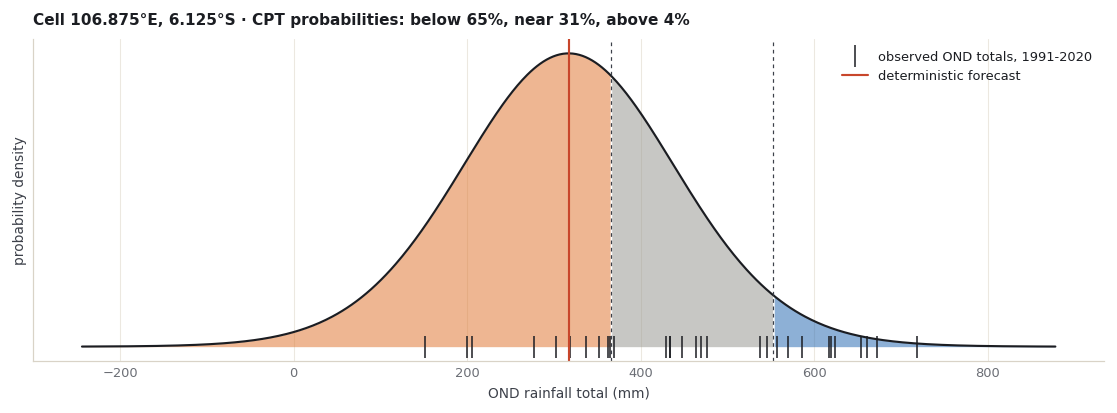

In [3]:
lon, lat = 106.875, -6.125   # the 0.25-degree cell centred near Jakarta
f0 = float(forecast.deterministic.sel(X=lon, Y=lat))
s0 = float(np.sqrt(forecast.prediction_error_variance.sel(X=lon, Y=lat)))
lo0, hi0 = float(lower.sel(X=lon, Y=lat)), float(upper.sel(X=lon, Y=lat))
observed_history = Y.sel(X=lon, Y=lat).values
nu = 26

x = np.linspace(f0 - 4.5 * s0, f0 + 4.5 * s0, 600)
density = student_t.pdf((x - f0) / s0, nu) / s0
fig, ax = plt.subplots(figsize=(10, 3.6), layout="constrained")
for mask, colour in zip([x <= lo0, (x > lo0) & (x < hi0), x >= hi0], figures.CATEGORY_COLOURS):
    ax.fill_between(x[mask], density[mask], color=colour, alpha=0.55, linewidth=0)
ax.plot(x, density, color=figures.INK, linewidth=1.4)
for edge in (lo0, hi0):
    ax.axvline(edge, color=figures.INK_2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.plot(observed_history, np.zeros_like(observed_history), "|", color=figures.INK, markersize=14,
        label="observed OND totals, 1991-2020")
ax.axvline(f0, color=figures.MARK, linewidth=1.4, label="deterministic forecast")
cpt_probs = forecast.probabilistic.sel(X=lon, Y=lat).values
ax.set_title(f"Cell {lon}°E, {abs(lat)}°S · CPT probabilities: below {cpt_probs[0]:.0f}%, "
             f"near {cpt_probs[1]:.0f}%, above {cpt_probs[2]:.0f}%", fontsize=10)
ax.set(xlabel="OND rainfall total (mm)", ylabel="probability density", yticks=[])
ax.legend(loc="upper right")
plt.show()

The ticks along the bottom are the 30 observed OND totals that set the two dashed
boundaries. The coloured areas are the three probabilities. Notice that the curve
extends below 0 mm: the t distribution is unbounded, so it gives a small
probability to totals that rainfall cannot have. That is part of the model, not of
the data.

Now the same calculation for every cell, compared with the probabilities CPT
wrote. It also tries ν = 30, the training sample size, to show that the choice is
visible in the numbers.

In [4]:
centre = forecast.deterministic
scale = np.sqrt(forecast.prediction_error_variance)
cpt_below = forecast.probabilistic.isel(C=0)
cpt_above = forecast.probabilistic.isel(C=2)

rows = []
for dof in (26, 30):
    below = xr.apply_ufunc(student_t.cdf, (lower - centre) / scale, dof) * 100
    above = xr.apply_ufunc(student_t.sf, (upper - centre) / scale, dof) * 100
    rows.append({"degrees of freedom": dof,
                 "largest difference, below normal (pp)": float(abs(below - cpt_below).where(cells).max()),
                 "largest difference, above normal (pp)": float(abs(above - cpt_above).where(cells).max())})
print("Cells where the deterministic forecast is exactly zero:", int((centre == 0).where(cells).sum()))
pd.DataFrame(rows).set_index("degrees of freedom").round(4)

Cells where the deterministic forecast is exactly zero: 0


,"largest difference, below normal (pp)","largest difference, above normal (pp)"
degrees of freedom,,
26,0.0010,0.0011
30,0.0801,0.0802


With ν = 26 the rebuilt probabilities match CPT's to about a thousandth of a
percentage point, the precision of CPT's text output; with ν = 30 the gap is about
0.08 percentage points, roughly seventy times larger. The rule is confirmed for
this forecast.

One more detail, from CPT's [release notes](https://cptplus.org/whatsnew.html)
(version 17.1.1): CPT sets negative rainfall forecasts to zero *after* computing the
probabilities, so at such cells the saved deterministic value
is not the distribution's centre. This forecast has no zero cells, as the first line
of output shows, so the saved values can be used directly.

## 4. Reading the three maps together

The most-likely-category map in chapter 4 hides how confident each cell is. The
three category maps show all of it.

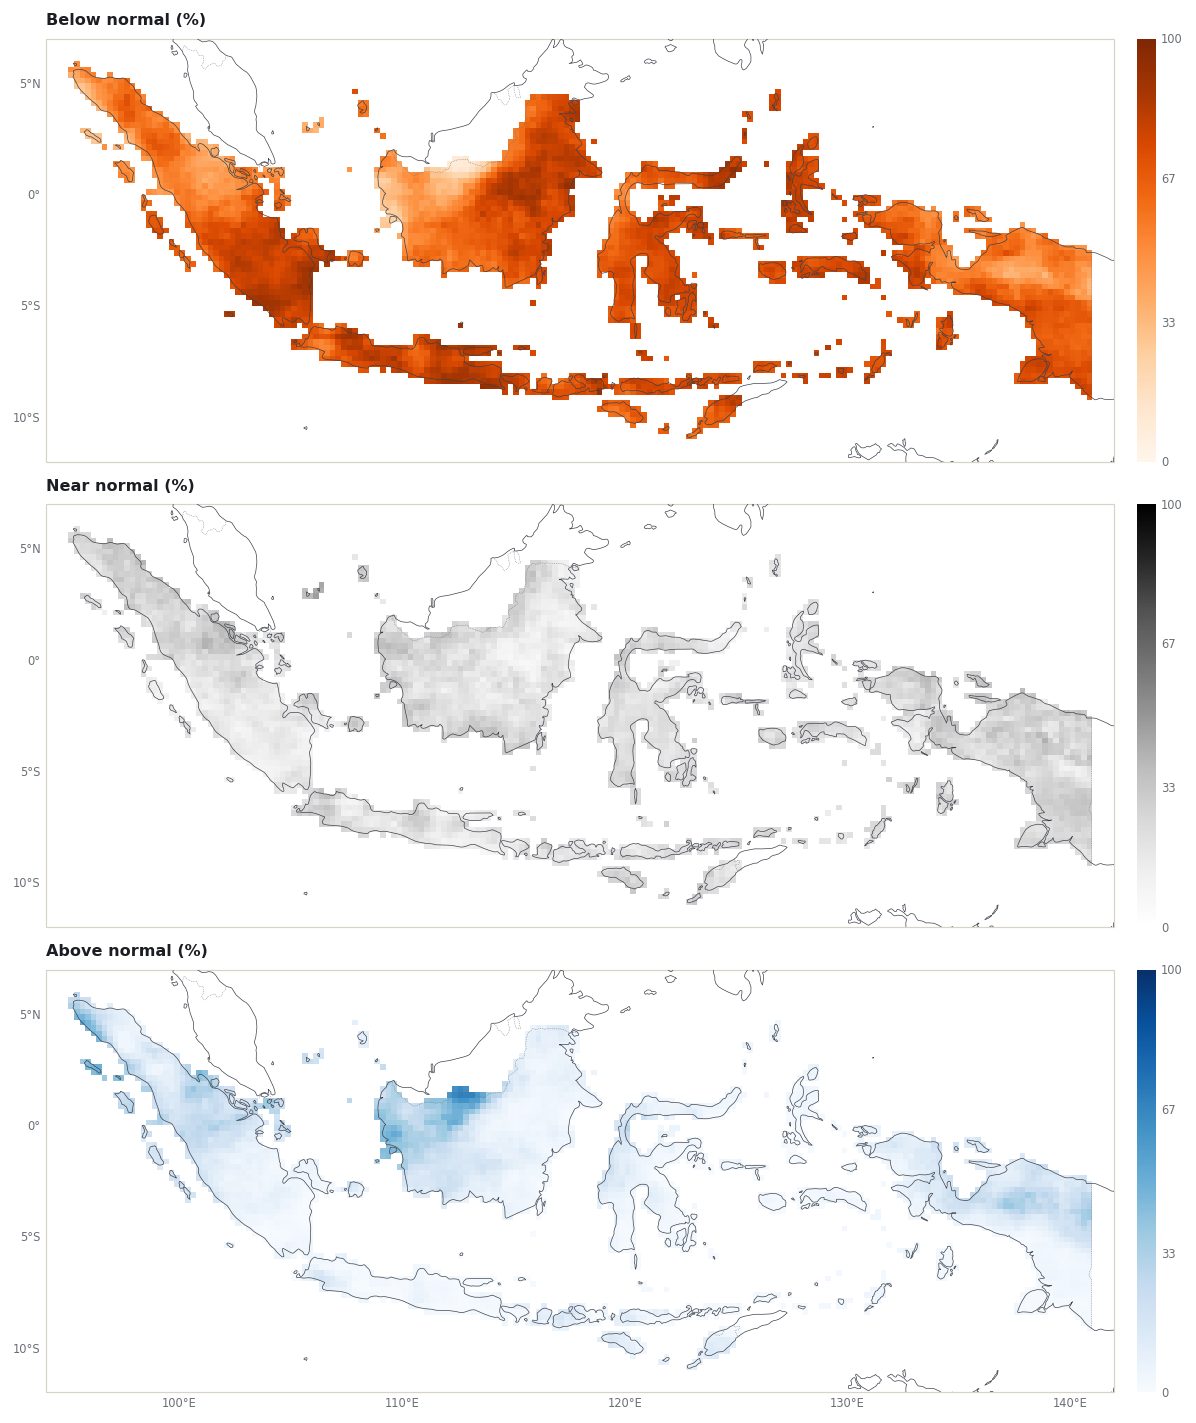

Most likely category, share of cells (%): {'below normal': 96.0, 'near normal': 0.6, 'above normal': 3.4}
Cells where the leading category has more than 50%: 87.9%
Largest probability for any category in any cell: 93.6%


In [5]:
figures.tercile_maps(forecast.probabilistic, predictand_box)
plt.show()

top = forecast.probabilistic.max("C").where(cells)
leading = forecast.probabilistic.fillna(-1).argmax("C").where(cells)
shares = {name: float((leading == i).sum() / cells.sum() * 100)
          for i, name in enumerate(["below normal", "near normal", "above normal"])}
print("Most likely category, share of cells (%):", {k: round(v, 1) for k, v in shares.items()})
print(f"Cells where the leading category has more than 50%: {float((top > 50).sum() / cells.sum() * 100):.1f}%")
print(f"Largest probability for any category in any cell: {float(top.max()):.1f}%")

## 5. Flexible forecasts: ask your own question

A tercile map answers one question. PyCPT's `construct_flex_fcst` answers others,
for example *what is the chance of less than the driest fifth of past seasons?* or
*of more than 600 mm?* It returns the probability of exceeding a threshold given
either as a percentile of the training observations or as a value in mm. The
operational template uses it for its "flexible forecast" maps.

First, a check. Asking for the probability of exceeding the 67th percentile should
reproduce CPT's "above normal" probability. It comes close, but not exactly:

In [6]:
import warnings

# Y has no values over the sea. construct_flex_fcst takes percentiles of every cell,
# so NumPy warns about those all-missing cells; the warning is expected and silenced.
warnings.filterwarnings("ignore", message="All-NaN slice encountered")

cpt_args = {"transform_predictand": None, "tailoring": None}
exceed67, flex_scale, _, flex_centre, _, _, ntrain, flex_threshold = pycpt.construct_flex_fcst(
    "CCA", cpt_args, centre, 0.67, True, Y, forecast.prediction_error_variance)
gap = (exceed67 * 100 - cpt_above).where(cells)
print(f"construct_flex_fcst(67th percentile) minus CPT above normal: largest {float(abs(gap).max()):.2f} pp, "
      f"mean {float(abs(gap).mean()):.2f} pp")

construct_flex_fcst(67th percentile) minus CPT above normal: largest 2.02 pp, mean 0.45 pp


The installed PyCPT 2.10.4 source of `construct_flex_fcst` makes three choices
that differ from CPT's native calculation:

| | CPT 17.8.3 native | `construct_flex_fcst` |
| --- | --- | --- |
| Percentile threshold | `hazen` rule | `Y.quantile`, xarray's default (linear) rule |
| Degrees of freedom | N − 4 = 26 | N = 30 |
| Scale | √(prediction-error variance) | √((N − 2)/N × prediction-error variance) |

The next cell switches the native calculation over to each choice one at a time,
to show how much each contributes.

In [7]:
def exceed(threshold, dof, scale_factor):
    return xr.apply_ufunc(student_t.sf, (threshold - centre) / (scale * scale_factor), dof) * 100

linear67 = Y.quantile(0.67, dim="T").drop_vars("quantile").where(cells)
variants = {
    "native (hazen, 26, full scale)": exceed(upper, 26, 1.0),
    "only the threshold rule changed": exceed(linear67, 26, 1.0),
    "only the degrees of freedom changed": exceed(upper, 30, 1.0),
    "only the scale changed": exceed(upper, 26, np.sqrt(28 / 30)),
    "all three changed": exceed(linear67, 30, np.sqrt(28 / 30)),
}
rows = [{"variant": k, "largest difference from CPT (pp)": float(abs(v - cpt_above).where(cells).max()),
         "mean difference from CPT (pp)": float(abs(v - cpt_above).where(cells).mean())} for k, v in variants.items()]
print("All three changed equals construct_flex_fcst to within",
      f"{float(abs(variants['all three changed'] - exceed67 * 100).where(cells).max()):.1e} pp")
pd.DataFrame(rows).set_index("variant").round(3)

All three changed equals construct_flex_fcst to within 2.8e-14 pp


,largest difference from CPT (pp),mean difference from CPT (pp)
variant,,
"native (hazen, 26, full scale)",0.001,0.000
only the threshold rule changed,2.559,0.236
only the degrees of freedom changed,0.080,0.063
only the scale changed,0.819,0.561
all three changed,2.020,0.449


The threshold rule has the largest effect on its own. The three effects partly
cancel, so all three together differ from CPT by less than the threshold change
alone.

Both calculations are internally consistent; they make different statistical
choices, and neither choice is shown here to be better calibrated. What matters
in practice is to **say which one a map uses**, and not to present a
`construct_flex_fcst` map as CPT's native probabilities.

With that understood, `construct_flex_fcst` answers questions the tercile map
cannot. Here, the chance that OND 2023 falls below the driest fifth of the
1991-2020 seasons (the 20th percentile), and the chance it exceeds 600 mm:

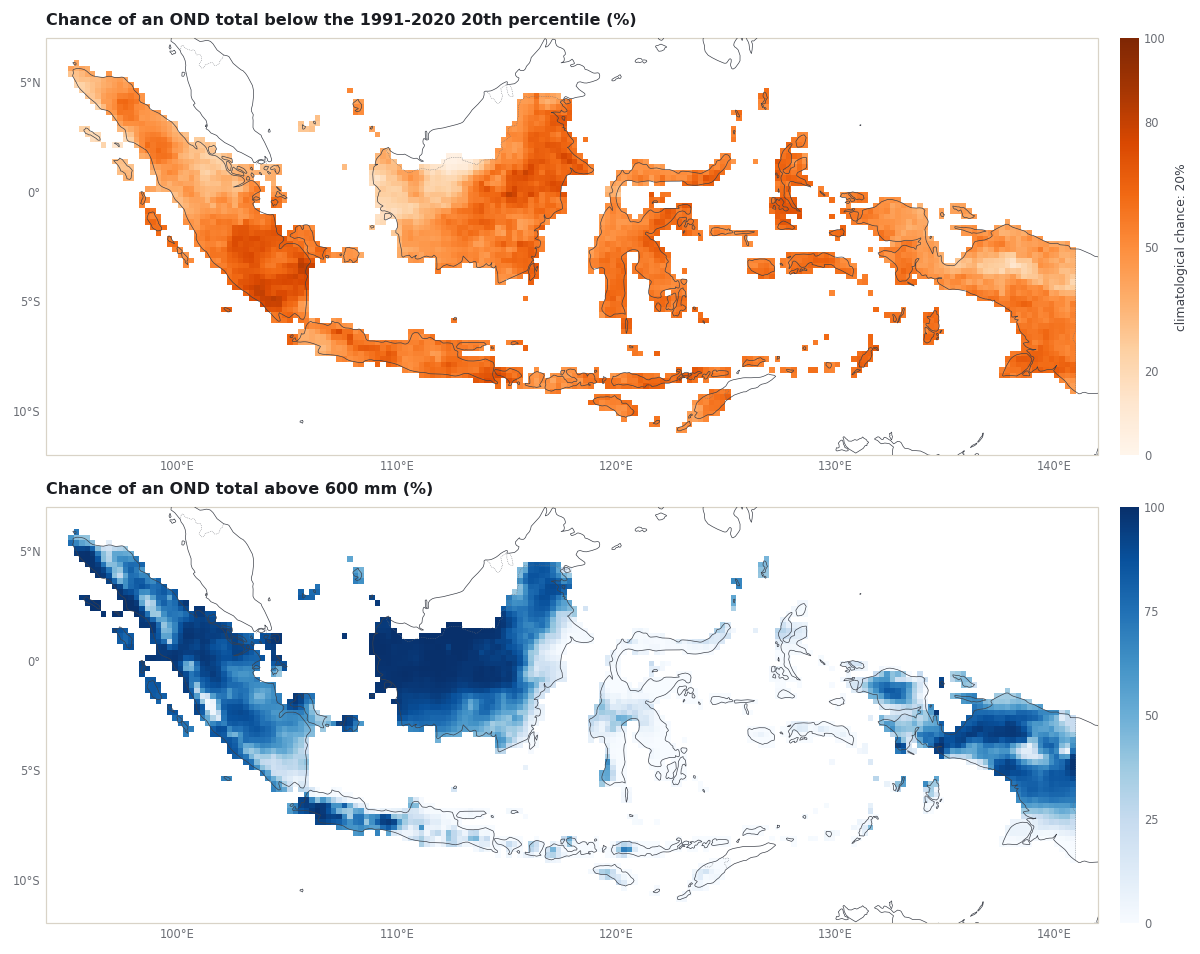

In [8]:
exceed20, *_ = pycpt.construct_flex_fcst("CCA", cpt_args, centre, 0.20, True, Y, forecast.prediction_error_variance)
exceed600, *_ = pycpt.construct_flex_fcst("CCA", cpt_args, centre, 600, False, Y, forecast.prediction_error_variance)
below20 = (1 - exceed20) * 100
above600 = exceed600 * 100

fig, grid = figures.stacked([figures.map_height(predictand_box)] * 2)
ax = figures.map_axes(fig, grid[0, 0], predictand_box)
image = figures.draw_field(ax, below20.where(cells), cmap="Oranges", vmin=0, vmax=100)
ax.set_title("Chance of an OND total below the 1991-2020 20th percentile (%)")
figures.colorbar(fig, image, ax, "climatological chance: 20%", ticks=[0, 20, 50, 80, 100])
ax = figures.map_axes(fig, grid[1, 0], predictand_box)
image = figures.draw_field(ax, above600.where(cells), cmap="Blues", vmin=0, vmax=100)
ax.set_title("Chance of an OND total above 600 mm (%)")
figures.colorbar(fig, image, ax, "", ticks=[0, 25, 50, 75, 100])
plt.show()

Both maps use `construct_flex_fcst`'s conventions from the table above. Like the
tercile probabilities, they assume the t distribution describes the forecast error
well. Nothing in this case tests that assumption; checking it needs many forecasts
compared with what happened, which chapter 4's in-sample scores do not provide.

## 6. What happened in OND 2023

One season cannot show whether probabilities are reliable, but it does show how
to read a forecast against the outcome. The observed OND 2023 totals come from the
same CHIRPS v3.0 preparation as the training data, saved with the Fit & diagnose
case. Each cell is placed in a category with the same boundaries.

Observed season: 2023-10-01 to 2023-12-31


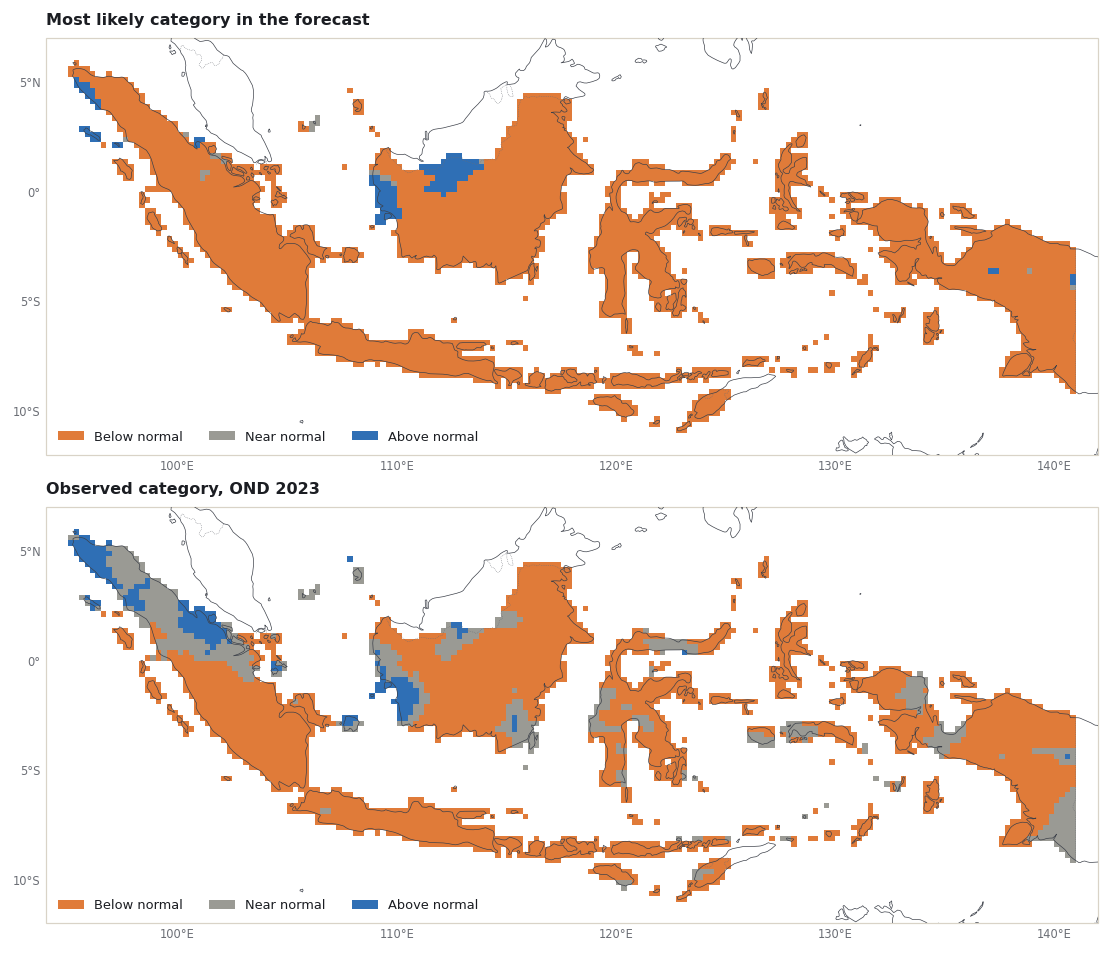

Observed category, share of cells (%): {'below normal': 76.7, 'near normal': 18.1, 'above normal': 5.1}
Cells where the most likely category was observed: 77.7%
Median probability the forecast gave to the observed category: 67.9% (a climatological forecast gives 33 or 34%)


In [9]:
context = xr.open_dataset(repo / "docs/data/fitting-2023/comparison-context.nc")
observed = context.observed_rainfall.sel(season="OND").reset_coords(drop=True).where(cells)
print("Observed season:", str(context.target_start.sel(season="OND").values)[:10], "to",
      str(context.target_end.sel(season="OND").values)[:10])

observed_category = xr.where(observed < lower, 0, xr.where(observed > upper, 2, 1)).where(cells)
probability_of_outcome = forecast.probabilistic.isel(C=0).where(observed_category == 0, 0) \
    + forecast.probabilistic.isel(C=1).where(observed_category == 1, 0) \
    + forecast.probabilistic.isel(C=2).where(observed_category == 2, 0)
probability_of_outcome = probability_of_outcome.where(cells)

fig, grid = figures.stacked([figures.map_height(predictand_box)] * 2)
ax = figures.map_axes(fig, grid[0, 0], predictand_box)
figures.category_map(ax, leading)
ax.set_title("Most likely category in the forecast")
figures.category_legend(ax)
ax = figures.map_axes(fig, grid[1, 0], predictand_box)
figures.category_map(ax, observed_category)
ax.set_title("Observed category, OND 2023")
figures.category_legend(ax)
plt.show()

observed_shares = {name: round(float((observed_category == i).sum() / cells.sum() * 100), 1)
                   for i, name in enumerate(["below normal", "near normal", "above normal"])}
print("Observed category, share of cells (%):", observed_shares)
print(f"Cells where the most likely category was observed: {float((leading == observed_category).sum() / cells.sum() * 100):.1f}%")
print(f"Median probability the forecast gave to the observed category: {float(probability_of_outcome.median()):.1f}%"
      " (a climatological forecast gives 33 or 34%)")

These numbers describe one season over spatially connected cells. Neighbouring
cells share weather, so 3,240 cells are not 3,240 independent tests, and a good or
poor match in one year says little about the next. Judging probability forecasts
needs many seasons of out-of-sample forecasts, scored with measures such as the
ranked probability skill score and reliability diagrams.

## What you have now

- The rule behind CPT's tercile probabilities, rebuilt and matched to CPT's output.
- The three category maps, read together, and the forecast's confidence.
- PyCPT's `construct_flex_fcst`, its three differences from the native calculation
  and how much each contributes, plus two practical threshold maps.
- A one-season comparison with what was observed, and why it is not a skill test.

The next chapter combines several models into a multi-model ensemble with
`construct_mme`.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
3. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
4. CPT+. *Forecast Probabilities* (CPT help). <https://cptplus.org/Help/Tools_Forecast_Probs.html> Same page name as on the former cpthelp.iri.columbia.edu, which did not resolve when checked on 10 November 2026.
5. CPT+. *Customising the Results* (CPT help). <https://cptplus.org/Help/CPT_use_custom.html>
6. CPT+. *What's New* (CPT release history). <https://cptplus.org/whatsnew.html>
7. IRI. *CPT 17.8.3 source code archive*. Columbia University Academic Commons. <https://doi.org/10.7916/fdp6-v391>
8. SciPy. *scipy.stats.t* (SciPy manual). <https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html>
9. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
10. xarray. *xarray.DataArray.quantile* (API reference). <https://docs.xarray.dev/en/stable/generated/xarray.DataArray.quantile.html>
11. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
12. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>